# Iris Species Classification

**Question:** Can four flower measurements predict iris species better than a majority-class baseline?

Compare scaled logistic regression and scaled k-nearest neighbors using training-only cross-validation. Choose the model by mean macro F1, then evaluate the selected model once on a held-out set. Macro F1 weights the three species equally. Accuracy measures the fraction of correct labels.

The purpose is to learn a defensible evaluation workflow on a small classic dataset, not to claim a new research result.


In [1]:
from pathlib import Path
import hashlib
import json
import platform
import importlib.metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT = Path.cwd()
if not (ROOT / "data").exists():
    raise RuntimeError("Run this notebook from the project folder containing data/.")
OUT = ROOT / "results"
OUT.mkdir(exist_ok=True)
SEED = 42
plt.rcParams.update({"figure.dpi": 120, "savefig.dpi": 150,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titlesize": 15, "font.size": 10})
COLORS = ["#167D9A", "#E59236", "#7557A5"]

def savefig(name):
    plt.tight_layout()
    plt.savefig(OUT / name, bbox_inches="tight", facecolor="white")
    plt.show()
    plt.close()

def save_json(name, obj):
    (OUT / name).write_text(json.dumps(obj, indent=2, allow_nan=False) + "\n", encoding="utf-8")

def verify_source(filename):
    manifest = json.loads((ROOT / "data" / "provenance.json").read_text())
    actual = hashlib.sha256((ROOT / "data" / filename).read_bytes()).hexdigest()
    assert actual == manifest["sha256"], "The raw data changed; review provenance before rerunning."
    return manifest

save_json("environment.json", {"python": platform.python_version(), **{
    p: importlib.metadata.version(p) for p in ["numpy", "pandas", "matplotlib", "scikit-learn", "nbclient", "nbformat"]}})


## 1. Audit and document preprocessing

Source: [UCI Iris](https://archive.ics.uci.edu/dataset/53/iris), Fisher (1936), [DOI](https://doi.org/10.24432/C56C76), CC BY 4.0. The raw file remains unchanged. UCI documents two erroneous records; the corrections below apply to 1-based rows 35 and 38. All four measurements use centimeters.

After those documented corrections, remove identical feature-and-label rows conservatively to avoid putting the same measurement vector into training and test data. Rounded measurements can coincide for different plants, so deduplication is a modeling choice, not evidence of faulty collection. Row IDs retain their original 0-based positions.


In [2]:
verify_source("iris.data")
features = ["sepal_length_cm", "sepal_width_cm", "petal_length_cm", "petal_width_cm"]
raw = pd.read_csv(ROOT / "data/iris.data", header=None, names=features + ["species"])
assert raw.shape == (150, 5) and not raw.isna().any().any()
corrected = raw.copy()
corrected.loc[34, "petal_width_cm"] = 0.2
corrected.loc[37, ["sepal_width_cm", "petal_length_cm"]] = [3.6, 1.4]
df = corrected.drop_duplicates().copy()
duplicates_removed = len(raw) - len(df)
print(f"Raw rows: {len(raw)}; identical rows removed after corrections: {duplicates_removed}; retained: {len(df)}")
display(df.head())
display(df.species.value_counts().rename("count").to_frame())
assert df[features].gt(0).all().all()
assert set(df.species) == {"Iris-setosa", "Iris-versicolor", "Iris-virginica"}


Raw rows: 150; identical rows removed after corrections: 1; retained: 149


,sepal_length_cm,sepal_width_cm,petal_length_cm,petal_width_cm,species
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa


,count
species,
Iris-setosa,50
Iris-versicolor,50
Iris-virginica,49


## 2. Set aside test data before model exploration

Use a reproducible 80/20 stratified split to preserve class proportions. The small test sample makes its score uncertain. Scaling lives inside a pipeline, so each cross-validation fold learns its scaling parameters from that fold's training subset only. The test set does not choose models or parameters.


Training: 119 rows; test: 30 rows


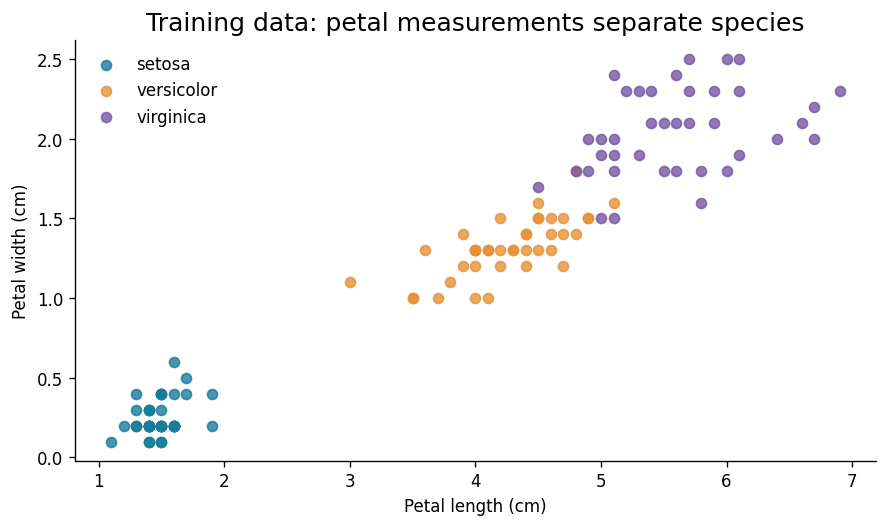

In [3]:
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay
from sklearn.base import clone

X_train, X_test, y_train, y_test = train_test_split(
    df[features], df.species, test_size=0.2, random_state=SEED, stratify=df.species)
assert set(X_train.index).isdisjoint(X_test.index)
assert not set(map(tuple, X_train.to_numpy())).intersection(map(tuple, X_test.to_numpy()))
save_json("split.json", {"train_row_ids": X_train.index.tolist(), "test_row_ids": X_test.index.tolist(),
                         "seed": SEED, "strategy": "stratified 80/20 after documented corrections and deduplication"})
print(f"Training: {len(X_train)} rows; test: {len(X_test)} rows")
fig, ax = plt.subplots(figsize=(7.5, 4.5))
for color, species in zip(COLORS, sorted(y_train.unique())):
    group = X_train.loc[y_train == species]
    ax.scatter(group.petal_length_cm, group.petal_width_cm, label=species.replace("Iris-", ""), color=color, alpha=0.8)
ax.set(xlabel="Petal length (cm)", ylabel="Petal width (cm)", title="Training data: petal measurements separate species")
ax.legend(frameon=False)
savefig("training_petals.png")


## 3. Compare fixed candidate models

The baseline predicts the most frequent training class. Logistic regression learns linear class boundaries; 5-nearest neighbors predicts from nearby scaled measurements. Candidate settings are fixed in advance. Five shuffled stratified folds estimate performance within the training data. Standard deviations describe variation across folds, not a confidence interval for deployment accuracy.


,model,cv_accuracy_mean,cv_macro_f1_mean,cv_macro_f1_sd
1,logistic_regression,0.9656,0.9629,0.0622
2,knn_5,0.9572,0.9561,0.0554
0,majority_baseline,0.3362,0.1677,0.0024


Selected using training-only macro F1: logistic_regression


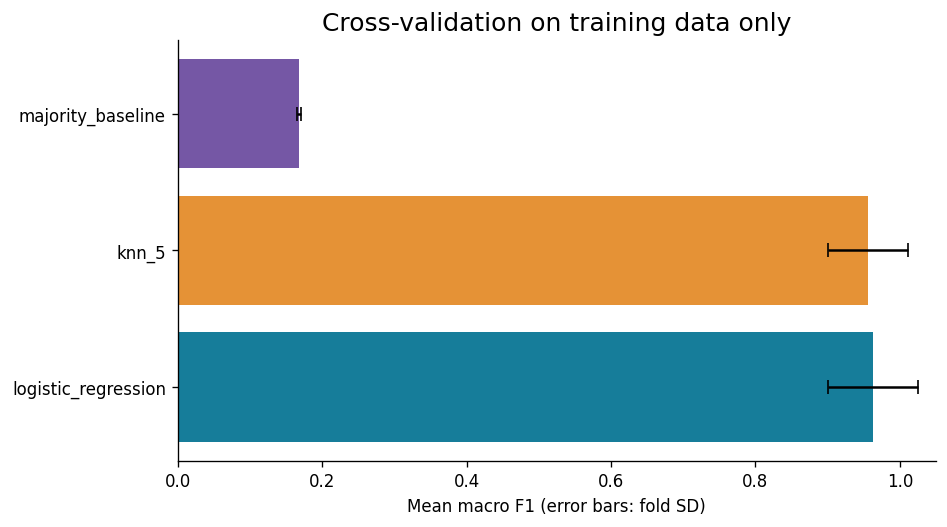

In [4]:
models = {
    "majority_baseline": DummyClassifier(strategy="most_frequent"),
    "logistic_regression": make_pipeline(StandardScaler(), LogisticRegression(C=1.0, max_iter=2000, random_state=SEED)),
    "knn_5": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)),
}
folds = list(StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED).split(X_train, y_train))
for fit_idx, val_idx in folds:
    assert set(X_train.index[fit_idx]).isdisjoint(X_train.index[val_idx])
    assert set(X_train.index[val_idx]).isdisjoint(X_test.index)
cv_rows = []
for name, model in models.items():
    scores = cross_validate(model, X_train, y_train, cv=folds,
                            scoring={"accuracy": "accuracy", "macro_f1": "f1_macro"}, error_score="raise")
    cv_rows.append({"model": name, "cv_accuracy_mean": scores["test_accuracy"].mean(),
                    "cv_macro_f1_mean": scores["test_macro_f1"].mean(),
                    "cv_macro_f1_sd": scores["test_macro_f1"].std(ddof=1)})
cv_results = pd.DataFrame(cv_rows).sort_values(["cv_macro_f1_mean", "model"], ascending=[False, True])
selected_name = cv_results.iloc[0].model
display(cv_results.round(4))
print("Selected using training-only macro F1:", selected_name)
cv_results.to_csv(OUT / "cross_validation.csv", index=False)
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(cv_results.model, cv_results.cv_macro_f1_mean, xerr=cv_results.cv_macro_f1_sd,
        color=COLORS, capsize=4)
ax.set(xlabel="Mean macro F1 (error bars: fold SD)", xlim=(0, 1.05), title="Cross-validation on training data only")
savefig("model_comparison.png")


## 4. Final held-out evaluation

Fit the chosen pipeline on all training rows, then predict the untouched test rows. Compare the baseline using the same test set. Inspect the confusion matrix and error rows instead of reporting accuracy alone. The Wilson interval gives an approximate 95% binomial interval for accuracy, conditional on this held-out sample and its independence assumption.


,precision,recall,f1-score,support
Iris-setosa,1.000,1.000,1.000,10.000
Iris-versicolor,0.900,0.900,0.900,10.000
Iris-virginica,0.900,0.900,0.900,10.000
accuracy,0.933,0.933,0.933,0.933
macro avg,0.933,0.933,0.933,30.000
weighted avg,0.933,0.933,0.933,30.000


Misclassified test rows:


,sepal_length_cm,sepal_width_cm,petal_length_cm,petal_width_cm,actual,predicted,correct
77,6.7,3.0,5.0,1.7,Iris-versicolor,Iris-virginica,False
134,6.1,2.6,5.6,1.4,Iris-virginica,Iris-versicolor,False


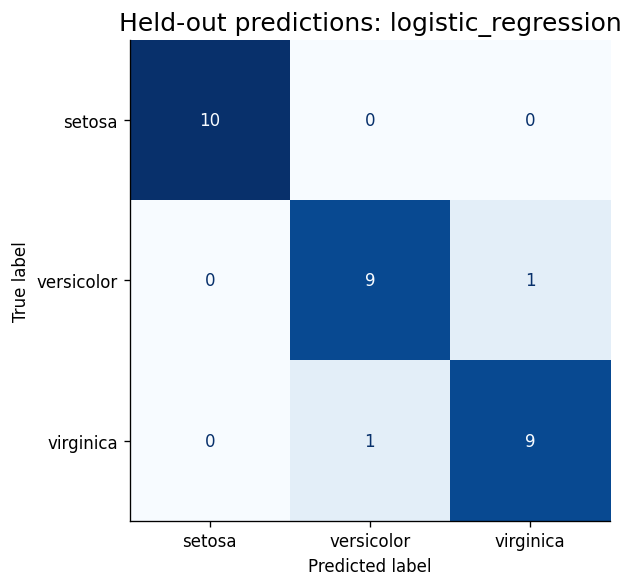

**Result:** logistic_regression correctly labels **28/30** flowers (accuracy 93.3%, macro F1 0.933). Baseline accuracy: 33.3%. Approximate accuracy interval: 78.7%–98.2%.

In [5]:
selected = clone(models[selected_name]).fit(X_train, y_train)
pred = selected.predict(X_test)
baseline = clone(models["majority_baseline"]).fit(X_train, y_train)
baseline_pred = baseline.predict(X_test)
accuracy = accuracy_score(y_test, pred)
macro_f1 = f1_score(y_test, pred, average="macro")
n = len(y_test)
z = 1.96
denom = 1 + z*z/n
center = (accuracy + z*z/(2*n))/denom
half = z*np.sqrt(accuracy*(1-accuracy)/n + z*z/(4*n*n))/denom
accuracy_ci = [max(0.0, center-half), min(1.0, center+half)]
report = classification_report(y_test, pred, output_dict=True, zero_division=0)
display(pd.DataFrame(report).T.round(3))
pd.DataFrame(report).T.to_csv(OUT / "classification_report.csv")
predictions = X_test.copy()
predictions["actual"] = y_test
predictions["predicted"] = pred
predictions["correct"] = y_test.to_numpy() == pred
predictions.to_csv(OUT / "test_predictions.csv", index_label="raw_row_id")
print("Misclassified test rows:")
display(predictions.loc[~predictions.correct])
fig, ax = plt.subplots(figsize=(6.5, 5))
ConfusionMatrixDisplay.from_predictions(y_test, pred, labels=sorted(df.species.unique()),
    display_labels=["setosa", "versicolor", "virginica"], colorbar=False, cmap="Blues", ax=ax)
ax.set_title(f"Held-out predictions: {selected_name}")
savefig("confusion_matrix.png")
results = {"raw_rows": len(raw), "rows_after_deduplication": len(df), "duplicates_removed": duplicates_removed,
           "train_rows": len(X_train), "test_rows": n, "selected_model": selected_name,
           "test_accuracy": float(accuracy), "test_macro_f1": float(macro_f1),
           "accuracy_wilson_95": accuracy_ci,
           "baseline_test_accuracy": float(accuracy_score(y_test, baseline_pred)),
           "baseline_test_macro_f1": float(f1_score(y_test, baseline_pred, average="macro")),
           "correct_predictions": int((pred == y_test.to_numpy()).sum()),
           "cross_validation": cv_results.to_dict(orient="records")}
assert np.isfinite([accuracy, macro_f1, *accuracy_ci]).all()
save_json("metrics.json", results)
display(Markdown(f"**Result:** {selected_name} correctly labels **{results['correct_predictions']}/{n}** flowers "
                 f"(accuracy {accuracy:.1%}, macro F1 {macro_f1:.3f}). Baseline accuracy: "
                 f"{results['baseline_test_accuracy']:.1%}. Approximate accuracy interval: "
                 f"{accuracy_ci[0]:.1%}–{accuracy_ci[1]:.1%}."))


## Conclusions and limits

The notebook reports the selected model's actual test performance above. Petal measurements visually separate the training classes, and preprocessing remains inside each fold. The dataset is small, balanced, old, and curated; its scores cannot establish performance on arbitrary flowers or photographs. The model only accepts numeric measurements from the three represented species.

The test result is a one-time check. Trying many seeds until accuracy improves would overfit the evaluation. A future comparison should use a new test set or nested cross-validation. Identical rounded records were removed conservatively; known source errors were corrected explicitly rather than silently.

**Next experiment:** compare petal-only and sepal-only models using training cross-validation, then evaluate any new selection on fresh labeled measurements.

**Learning checks:** Why fit the scaler inside each fold? Why does stratification help? Why can a perfect score on 30 observations still be uncertain?

**Assistance:** This educational project was developed with ChatGPT/Codex assistance. The code and results were executed and checked.
